# Designing a School-Level Experiment: Power Analysis

**Question:** If EIDU tested SMS reminders to teachers, how many schools would the experiment need to reliably detect an improvement in student learning?

This notebook works through the sample size calculation step by step, including why randomising schools (rather than individual students) changes the answer.

## Step 1: Sample size if we could randomise individual students

A **power calculation** tells us how many participants an experiment needs before we run it. Too few, and a real effect may not show up in the results.

Assumptions:
- **Effect size = 0.15 SD.** A light-touch intervention like an SMS reminder is likely to have a small effect, so I plan to detect a small improvement.
- **Significance level (alpha) = 0.05.** A 5% risk of concluding the intervention works when it doesn't.
- **Power = 0.8.** An 80% chance of detecting the effect if it is real.
- **Equal group sizes** for treatment and control.

In [ ]:
from statsmodels.stats.power import TTestIndPower
import math

analysis = TTestIndPower()

n_per_group = analysis.solve_power(
    effect_size=0.15,   # the improvement we want to detect (in SD)
    alpha=0.05,         # 5% risk of a false positive
    power=0.8,          # 80% chance of detecting a real effect
    ratio=1.0           # equal-sized treatment and control groups
)

print("Students needed per group:", math.ceil(n_per_group))
print("Total students:", math.ceil(n_per_group) * 2)

Students needed per group: 699
Total students: 1398


**Result:** If students could be randomised individually, the experiment would need about **699 students per group** (**1,398 in total**) to detect a 0.15 SD effect.

But this assumes every student is independent of every other student, which is not true in schools.

## Step 2: Adjusting for school-level randomisation

The SMS goes to the **teacher**, so the whole class is affected. That means we must randomise **schools**, not students.

Students in the same school share teachers, resources and surroundings, so their results tend to be similar. The **intra-cluster correlation (ICC)** measures this similarity on a scale from 0 (not similar at all) to 1 (identical). For learning outcomes, values between about 0.1 and 0.3 are common.

The **design effect** shows how much larger the sample must be to account for this:

**Design effect = 1 + (students per school − 1) × ICC**

Below I assume 30 tested students per school and compare a range of ICC values, since the true ICC is unknown before the study.

In [ ]:
students_per_school = 30
icc_values = [0.0, 0.05, 0.1, 0.2, 0.3]

n = math.ceil(n_per_group)

print(f"{'ICC':<6}{'Design effect':<16}{'Students/group':<17}{'Schools/group':<15}")
for icc in icc_values:
    design_effect = 1 + (students_per_school - 1) * icc
    students_needed = math.ceil(n * design_effect)
    schools_needed = math.ceil(students_needed / students_per_school)
    print(f"{icc:<6}{design_effect:<16.2f}{students_needed:<17}{schools_needed:<15}")

ICC   Design effect   Students/group   Schools/group  
0.0   1.00            699              24             
0.05  2.45            1713             58             
0.1   3.90            2727             91             
0.2   6.80            4754             159            
0.3   9.70            6781             227            


**Result:** With an ICC of 0.2, the experiment would need about **159 schools per group** (**318 schools in total**), compared with only **24 schools per group** if the ICC were 0.

**What this means:** As the ICC increases, the number of schools needed rises sharply, from 24 schools per group when students are fully independent to 159 schools per group at an ICC of 0.2. This happens because students in the same school tend to have similar results, so each additional student tested in a school adds less new information. To detect a small effect reliably, the experiment needs more schools rather than more students per school, which makes estimating the ICC from past data an important step before planning any school-level trial.

## Step 3: Visualising the effect of ICC on sample size

The chart below shows how many schools per group are needed as the ICC increases, assuming 30 students per school.

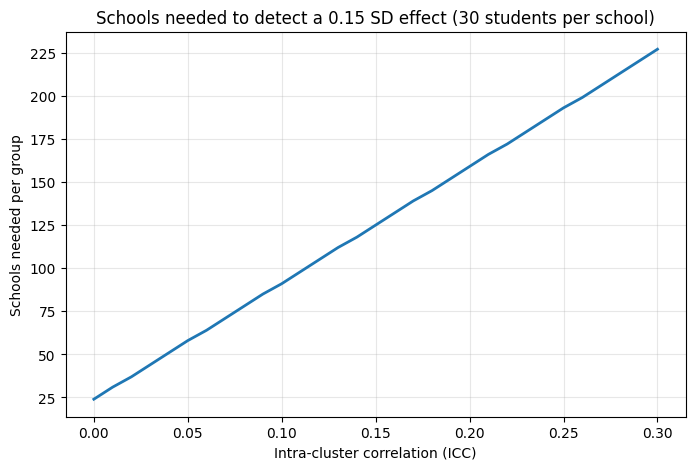

In [ ]:
import matplotlib.pyplot as plt  # library for making charts

# A smooth range of ICC values from 0 to 0.3
icc_range = [i / 100 for i in range(0, 31)]

# Calculate schools needed per group for each ICC value
schools_per_group = []
for icc in icc_range:
    design_effect = 1 + (students_per_school - 1) * icc
    students_needed = math.ceil(n * design_effect)
    schools_per_group.append(math.ceil(students_needed / students_per_school))

# Draw the chart
plt.figure(figsize=(8, 5))
plt.plot(icc_range, schools_per_group, linewidth=2)
plt.xlabel("Intra-cluster correlation (ICC)")
plt.ylabel("Schools needed per group")
plt.title("Schools needed to detect a 0.15 SD effect (30 students per school)")
plt.grid(alpha=0.3)
plt.show()

**Takeaway:** Even a modest ICC multiplies the number of schools required. Experiment budgets and timelines should be based on a realistic ICC estimate, ideally taken from existing learner data, rather than assuming students are independent.